In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## loss-landscape

**Figure 3: Training loss landscape of ResNet-56 (5.89% test error) on CIFAR-10 around the trained minimizer.** Contours show L(θ* + αδ + βη) along two filter-normalized random directions δ (Direction 1) and η (Direction 2), with the minimizer θ* at (0, 0), redrawn from Li et al. (2018), Figure 5(b). With skip connections the minimizer sits in a wide, nearly convex basin: the loss rises smoothly from 0.1 at the center to 9.6 along roughly elliptical contours.

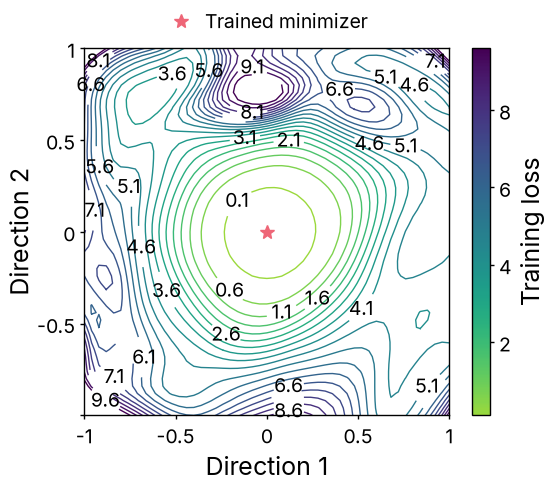

In [2]:
from matplotlib.colors import ListedColormap, Normalize

with open("../data/loss-landscape.json") as f:
    data = json.load(f)
levels = data["levels"]
cmap = ListedColormap(plt.get_cmap("viridis")(np.linspace(0.85, 0, 256)))
norm = Normalize(levels[0], levels[-1])

fig, ax = plt.subplots(figsize=(2.75, 2.75))
for line in data["contour_lines"]:
    xy = np.array(line["xy"])
    ax.plot(xy[:, 0], xy[:, 1], color=cmap(norm(line["level"])), linewidth=plt.rcParams["contour.linewidth"])
ax.plot(0, 0, "*", color=colors["ours"], markerfacecolor=colors["ours"],
        markersize=2 * plt.rcParams["lines.markersize"], linestyle="none", label="Trained minimizer")

ticks = [-1, -0.5, 0, 0.5, 1]
ax.set_xlim(data["x_range"])
ax.set_ylim(data["y_range"])
ax.set_xticks(ticks, labels=[f"{v:g}" for v in ticks])
ax.set_yticks(ticks, labels=["", *[f"{v:g}" for v in ticks[1:]]])
ax.grid(False)
ax.set_xlabel("Direction 1")
ax.set_ylabel("Direction 2")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=1, frameon=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="Training loss")
fit_height(fig, ax, aspect=1.0)

# with the final size set, keep the first of each group of level labels that would overlap
kept = []
for label in data["level_labels"]:
    t = ax.text(*label["xy"], f"{label['level']:.2g}", ha="center", va="center")
    box = t.get_window_extent(fig.canvas.get_renderer())
    if any(box.overlaps(k) for k in kept):
        t.remove()
    else:
        kept.append(box)

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/loss-landscape.pdf")
fig.savefig("../outputs/loss-landscape.png")
plt.show()